# Detecção de Imagens Sintéticas após Transformações

**Objetivo:** medir a robustez de features clássicas (FFT, HOG, LBP) + SVM no CIFAKE quando as imagens sofrem compressão, crop, resize, blur etc.

**Fluxo:** carregar dados → extrair features (só originais) → treinar SVM → aplicar transformações → medir queda de acurácia por feature.

> Desenvolvedores: Igor de Matos da Rosa e Nathália Geraldino Ribas

## 1. Setup e caminhos
Preparar o ambiente e apontar para o CIFAKE.

In [4]:
# Este bloco visa importar bibliotecas necessárias:
# - random (aleatoriedade)
# - numpy, pandas (dados e tabelas)
# - PIL / opencv (ler e transformar imagens)
# - skimage (HOG, LBP)
# - sklearn (SVM, métricas, StandardScaler)
# - matplotlib / seaborn (gráficos)
# - pathlib / os (caminhos)
# - joblib (salvar modelos .pkl)   
import os
import random
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from skimage.feature import hog, local_binary_pattern
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm import tqdm

In [5]:
# Define caminhos do projeto:
# - pasta raiz do repositório
# - caminho do CIFAKE ../Base/archive (bifurca em teste e treino)
# - pastas de saída: models/ e results/
# Fixar seed aleatória para reprodutibilidade

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define pastas
ROOT_DIR = Path.cwd()

# Tenta localizar a pasta archive
possible_dataset_paths = [
    ROOT_DIR / "Base" / "archive",
    ROOT_DIR.parent / "Base" / "archive",
    ROOT_DIR / "archive",
]

DATASET_DIR = None
for path in possible_dataset_paths:
    if path.exists():
        DATASET_DIR = path
        break

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Não foi possível encontrar a pasta 'Base/archive' contendo o dataset CIFAKE."
    )

# Bifurcação em treino e teste
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Pastas de saída: models/ e results/
MODELS_DIR = ROOT_DIR / "models"
RESULTS_DIR = ROOT_DIR / "results"

# Criar pastas de saída caso não existam
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Confirmação dos caminhos encontrados
print(f"Dataset encontrado em: {DATASET_DIR}")
print(f"Treino existe? {TRAIN_DIR.exists()}")
print(f"Teste existe? {TEST_DIR.exists()}")

Dataset encontrado em: /home/konath/Documentos/UFSC/VC/DeteccaoImagensSinteticas/Base/archive
Treino existe? True
Teste existe? True


## 2. Carregar o CIFAKE
Dataset balanceado REAL/FAKE, já separado em treino e teste.

In [6]:
# Função para listar imagens das pastas REAL/ e FAKE/
# Retornar: lista de caminhos + rótulos (0=FAKE, 1=REAL)
# Aplicar para train/ e test/
# Conferir quantas imagens há em cada classe

from pathlib import Path
from collections import Counter

def listar_imagens(pasta_base):
    caminhos = []
    rotulos = []

    classes = {
        "FAKE": 0,
        "REAL": 1
    }

    extensoes = {".jpg", ".jpeg", ".png"}

    for classe, rotulo in classes.items():
        pasta_classe = Path(pasta_base) / classe

        for imagem in pasta_classe.iterdir():
            if imagem.suffix.lower() in extensoes:
                caminhos.append(str(imagem))
                rotulos.append(rotulo)

    return caminhos, rotulos

def criar_subconjunto(caminhos, rotulos, quantidade_por_classe=500):
    fake = []
    real = []

    for caminho, rotulo in zip(caminhos, rotulos):
        if rotulo == 0 and len(fake) < quantidade_por_classe:
            fake.append((caminho, rotulo))

        elif rotulo == 1 and len(real) < quantidade_por_classe:
            real.append((caminho, rotulo))

    subconjunto = fake + real

    caminhos_sub = [item[0] for item in subconjunto]
    rotulos_sub = [item[1] for item in subconjunto]

    return caminhos_sub, rotulos_sub

train_caminhos, train_rotulos = listar_imagens("../Base/archive/train")
test_caminhos, test_rotulos = listar_imagens("../Base/archive/test")

print("Train:", Counter(train_rotulos))
print("Test:", Counter(test_rotulos))

Train: Counter({0: 50000, 1: 50000})
Test: Counter({0: 10000, 1: 10000})


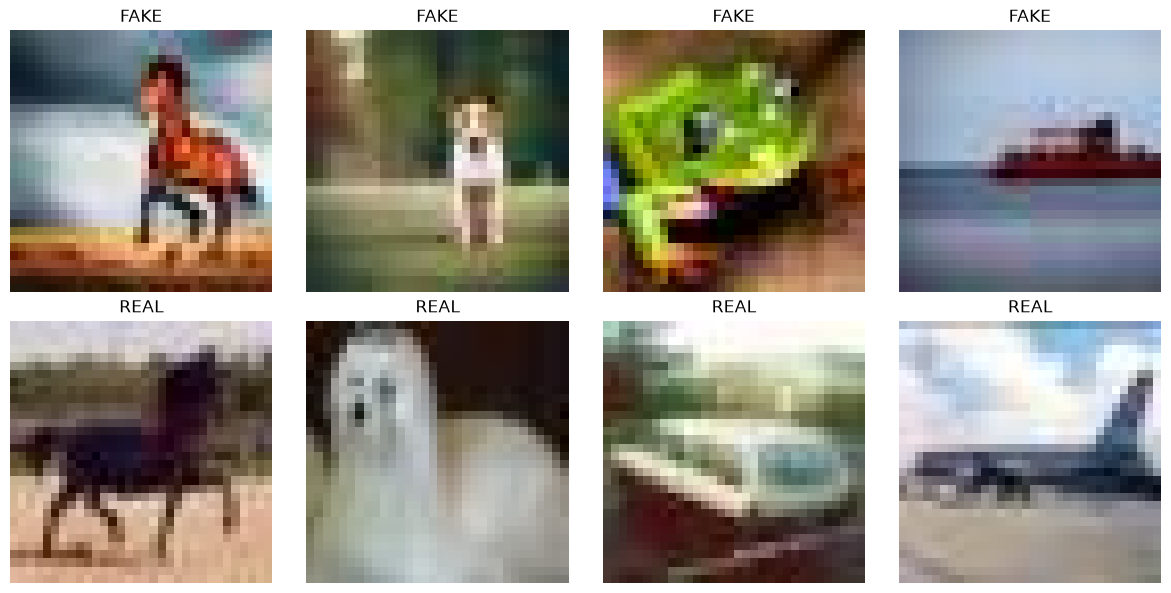

In [7]:
# Função para carregar uma imagem:
# - abrir arquivo
# - garantir tamanho consistente
# - converter para o formato usado nas features
# Mostrar exemplos (REAL e FAKE)

def carregar_imagem(caminho):
    imagem = cv2.imread(caminho)

    if imagem is None:
        raise ValueError(f"Não foi possível carregar a imagem: {caminho}")

    # Mantemos 32x32, tamanho original do CIFAKE
    imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    return imagem

import matplotlib.pyplot as plt

def mostrar_exemplos(caminhos, rotulos, quantidade=4):
    fake = []
    real = []

    for caminho, rotulo in zip(caminhos, rotulos):

        if rotulo == 0 and len(fake) < quantidade:
            fake.append(caminho)

        elif rotulo == 1 and len(real) < quantidade:
            real.append(caminho)

        if len(fake) == quantidade and len(real) == quantidade:
            break

    exemplos = fake + real

    plt.figure(figsize=(12, 6))

    for i, caminho in enumerate(exemplos):
        imagem = carregar_imagem(caminho)

        plt.subplot(2, quantidade, i + 1)
        plt.imshow(imagem)
        plt.axis("off")

        if i < quantidade:
            plt.title("FAKE")
        else:
            plt.title("REAL")

    plt.tight_layout()
    plt.show()

mostrar_exemplos(train_caminhos, train_rotulos)

## 3. Extratores de features
Três famílias alinhadas à disciplina: **frequência (FFT)**, **espaço (HOG)**, **textura (LBP)**.

In [8]:
# Implementa extrator FFT:
# - converte imagem para cinza
# - calcula FFT 2D e espectro de magnitude
# - shift para centralizar baixas frequências
# - transforma em vetor 1D
# - normaliza o vetor
# Testa em 1 imagem e imprimir o shape do vetor

def extrair_features_fft(imagem, num_bins=64):
    """Extrai o perfil azimutal (média radial) do espectro de magnitude da FFT 2D.

    - Converte para escala de cinza
    - Aplica FFT 2D com shift para centralizar frequências
    - Calcula o espectro de magnitude logarítmico
    - Reduz a um vetor 1D balanceado via média radial (histograma de frequências)
    - Normaliza o vetor (Escala [0, 1])
    """
    # 1. Converter para escala de cinza
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()

    # 2. Calcular FFT 2D
    fft_2d = np.fft.fft2(imagem_cinza)

    # 3. Shift para centralizar baixas frequências no meio do espectro
    fft_shifted = np.fft.fftshift(fft_2d)

    # Espectro de magnitude (com escala logarítmica para suavizar picos)
    magnitude_spectrum = np.log(np.abs(fft_shifted) + 1e-8)

    # 4. Transformar em vetor 1D via Média Radial (Perfil Azimutal de Frequência)
    h, w = magnitude_spectrum.shape
    centro_y, centro_x = h // 2, w // 2

    # Matriz de distâncias ao centro
    y, x = np.ogrid[:h, :w]
    raios = np.sqrt((x - centro_x) ** 2 + (y - centro_y) ** 2)

    # Binning radial para criar o vetor 1D
    raio_max = np.sqrt(centro_x**2 + centro_y**2)
    bins = np.linspace(0, raio_max, num_bins + 1)

    vetor_fft = np.zeros(num_bins)
    for i in range(num_bins):
        mascara = (raios >= bins[i]) & (raios < bins[i + 1])
        if np.any(mascara):
            vetor_fft[i] = np.mean(magnitude_spectrum[mascara])

    # 5. Normalizar o vetor 1D (Min-Max para [0, 1])
    min_val = np.min(vetor_fft)
    max_val = np.max(vetor_fft)
    if max_val - min_val > 1e-8:
        vetor_fft = (vetor_fft - min_val) / (max_val - min_val)

    return vetor_fft


# --- Teste em 1 imagem ---
img_teste = carregar_imagem(train_caminhos[0])
vetor_fft = extrair_features_fft(img_teste)

print(f"Classe da imagem de teste: {'REAL' if train_rotulos[0] == 1 else 'FAKE'}")
print(f"Shape do vetor de features FFT: {vetor_fft.shape}")
print("Primeiros valores do vetor normalizado:", np.round(vetor_fft[:5], 4))

Classe da imagem de teste: FAKE
Shape do vetor de features FFT: (64,)
Primeiros valores do vetor normalizado: [1.     0.     0.7904 0.     0.7858]


In [9]:
# Implementa extrator HOG:
# - usa skimage.feature.hog
# - define parâmetros razoáveis para 32x32 (pixels_per_cell, cells_per_block, orientations)
# - retorna o vetor de features
# Testa em 1 imagem e imprimir o shape do vetor

def extrair_features_hog(
    imagem,
    orientations=8,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
):
    """Extrai o vetor de características HOG de uma imagem 32x32.

    Parâmetros adequados para 32x32:
    - pixels_per_cell: (8, 8) divide a imagem em uma grade de 4x4 células.
    - cells_per_block: (2, 2) normaliza a iluminação em blocos 2x2 células.
    - orientations: 8 direções de gradientes (suficiente para 32x32).
    """
    
    # Converter para cinza se for imagem colorida
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()

    # Extração HOG
    vetor_hog = hog(
        imagem_cinza,
        orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        visualize=False,
    )

    return vetor_hog


# --- Teste em 1 imagem ---
img_teste = carregar_imagem(train_caminhos[0])
vetor_hog = extrair_features_hog(img_teste)

print(
    f"Classe da imagem de teste: {'REAL' if train_rotulos[0] == 1 else 'FAKE'}"
)
print(f"Shape do vetor de features HOG: {vetor_hog.shape}")
print("Primeiros valores do vetor HOG:", np.round(vetor_hog[:5], 4))

Classe da imagem de teste: FAKE
Shape do vetor de features HOG: (288,)
Primeiros valores do vetor HOG: [0.0614 0.0231 0.023  0.0192 0.0802]


In [10]:
# Implementa extrator LBP:
# - usa skimage.feature.local_binary_pattern
# - escolhe P (vizinhos) e R (raio)
# - monta histograma do LBP como vetor de features
# - normaliza o histograma
# Testa em 1 imagem e imprimir o shape do vetor

def extrair_features_lbp(imagem, P=8, R=1, method="uniform"):
    """Extrai o histograma normalizado do LBP de uma imagem 32x32.

    Parâmetros:
    - P: Número de pontos vizinhos circularmente simétricos (padrão: 8).
    - R: Raio do círculo para vizinhança (padrão: 1).
    - method: 'uniform' produz padrões invariantes a rotação e reduz
      o tamanho do vetor para P + 2 bins (10 bins para P=8).
    """
    # 1. Converter para escala de cinza se necessário
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()

    # 2. Calcular o mapa LBP
    lbp_mapa = local_binary_pattern(imagem_cinza, P=P, R=R, method=method)

    # 3. Montar o histograma do LBP como vetor de características
    # Para o método 'uniform', existem P + 2 bins
    n_bins = P + 2 if method == "uniform" else int(lbp_mapa.max() + 1)
    hist, _ = np.histogram(
        lbp_mapa.ravel(), bins=n_bins, range=(0, n_bins)
    )

    # 4. Normalizar o histograma (soma igual a 1)
    hist = hist.astype("float")
    soma = hist.sum()
    if soma > 0:
        hist /= soma

    return hist


# --- Teste em 1 imagem ---
img_teste = carregar_imagem(train_caminhos[0])
vetor_lbp = extrair_features_lbp(img_teste)

print(
    f"Classe da imagem de teste: {'REAL' if train_rotulos[0] == 1 else 'FAKE'}"
)
print(f"Shape do vetor de features LBP: {vetor_lbp.shape}")
print("Valores do histograma LBP normalizado:", np.round(vetor_lbp, 4))

Classe da imagem de teste: FAKE
Shape do vetor de features LBP: (10,)
Valores do histograma LBP normalizado: [0.0469 0.084  0.0732 0.1416 0.2666 0.1514 0.0557 0.0498 0.0449 0.0859]


In [11]:
# Função genérica: dado uma lista de caminhos + nome da feature ("fft"|"hog"|"lbp"),
# extrai features de todas as imagens e empilhar em matriz X
# Retornar X (n_amostras x n_features) e y (rótulos)
# Mostrar progresso (tqdm)
# Salva matrizes em disco (npz/npz) para não recalcular sempre · ./local · cria a pasta se não existir

def extrair_e_salvar_features(
    caminhos, rotulos, tipo_feature, pasta_saida="./local", nome_arquivo=None
):
    """Extrai features ('fft', 'hog' ou 'lbp') de uma lista de imagens,

    empilha em uma matriz X e salva em disco (.npz).
    """
    # 1. Mapeamento dos extratores
    extratores = {
        "fft": extrair_features_fft,
        "hog": extrair_features_hog,
        "lbp": extrair_features_lbp,
    }

    if tipo_feature not in extratores:
        raise ValueError(
            f"Tipo de feature '{tipo_feature}' inválido. Escolha entre: {list(extratores.keys())}"
        )

    funcao_extratora = extratores[tipo_feature]

    # 2. Loop de extração com tqdm
    features_list = []
    print(f"Extraindo features [{tipo_feature.upper()}]...")

    for caminho in tqdm(caminhos, desc=f"Processando ({tipo_feature})"):
        img = carregar_imagem(caminho)
        vetor = funcao_extratora(img)
        features_list.append(vetor)

    # 3. Empilhar em matrizes NumPy
    X = np.array(features_list)
    y = np.array(rotulos)

    # 4. Criar pasta de saída se não existir
    diretorio_saida = Path(pasta_saida)
    diretorio_saida.mkdir(parents=True, exist_ok=True)

    # 5. Salvar em disco
    if nome_arquivo is None:
        nome_arquivo = f"features_{tipo_feature}.npz"

    caminho_salvar = diretorio_saida / nome_arquivo
    np.savez_compressed(caminho_salvar, X=X, y=y)
    print(f"Matrizes salvas com sucesso em: {caminho_salvar}")

    return X, y

# --- Exemplo de teste com o subconjunto de treino ---
# X_train_hog, y_train_hog = extrair_e_salvar_features(train_caminhos, train_rotulos, tipo_feature="hog")
# print("Shape da matriz X:", X_train_hog.shape)
# print("Shape do vetor y:", y_train_hog.shape)

## 4. Features do conjunto ORIGINAL (treino e teste)
**Importante:** o SVM treina só em imagens **sem** transformação (baseline).

In [21]:
# Para cada tipo de feature (FFT, HOG, LBP):
# - extrair X_train, y_train a partir das imagens ORIGINAIS de treino
# - extrair X_test, y_test a partir das imagens ORIGINAIS de teste
# - aplicar StandardScaler (fit só no treino; transform no teste)
# Guardar em dicionários, ex.: features["hog"]["X_train"], etc.

train_caminhos_usados, train_rotulos_usados = train_caminhos, train_rotulos
test_caminhos_usados, test_rotulos_usados = test_caminhos, test_rotulos

print("Treino:", len(train_caminhos_usados), len(train_rotulos_usados))
print("Teste:", len(test_caminhos_usados), len(test_rotulos_usados))

print("Classes no treino:", np.unique(train_rotulos_usados, return_counts=True))
print("Classes no teste:", np.unique(test_rotulos_usados, return_counts=True))

tipos_features = ["fft", "hog", "lbp"]

features = {}
scalers = {}

for tipo in tipos_features:
    print(f"\nProcessando {tipo.upper()}")
    X_train_original, y_train = extrair_e_salvar_features(
        caminhos=train_caminhos_usados,
        rotulos=train_rotulos_usados,
        tipo_feature=tipo,
        pasta_saida="./local",
        nome_arquivo=f"features_{tipo}_train.npz"
    )

    X_test_original, y_test = extrair_e_salvar_features(
        caminhos=test_caminhos_usados,
        rotulos=test_rotulos_usados,
        tipo_feature=tipo,
        pasta_saida="./local",
        nome_arquivo=f"features_{tipo}_test.npz"
    )

    # Verifica se matrizes e rótulos são compatíveis e contêm valores válidos.
    assert X_train_original.shape[0] == y_train.shape[0]
    assert X_test_original.shape[0] == y_test.shape[0]
    assert X_train_original.shape[1] == X_test_original.shape[1]
    assert np.isfinite(X_train_original).all()
    assert np.isfinite(X_test_original).all()

    # Ajusta o scaler somente no treino e usa as mesmas estatísticas no teste.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_original)
    X_test_scaled = scaler.transform(X_test_original)

    # Organiza os dados para o treinamento dos SVMs na próxima seção.
    features[tipo] = {
        "X_train": X_train_scaled,
        "y_train": y_train,
        "X_test": X_test_scaled,
        "y_test": y_test,
    }
    scalers[tipo] = scaler

    print("Treino:", X_train_scaled.shape, "| Teste:", X_test_scaled.shape)
    print("Classes no treino:", np.unique(y_train, return_counts=True))
    print("Classes no teste:", np.unique(y_test, return_counts=True))

Treino: 100000 100000
Teste: 20000 20000
Classes no treino: (array([0, 1]), array([50000, 50000]))
Classes no teste: (array([0, 1]), array([10000, 10000]))

Processando FFT
Extraindo features [FFT]...


Processando (fft): 100%|██████████| 100000/100000 [02:05<00:00, 797.03it/s]


Matrizes salvas com sucesso em: local/features_fft_train.npz
Extraindo features [FFT]...


Processando (fft): 100%|██████████| 20000/20000 [00:22<00:00, 870.22it/s]


Matrizes salvas com sucesso em: local/features_fft_test.npz
Treino: (100000, 64) | Teste: (20000, 64)
Classes no treino: (array([0, 1]), array([50000, 50000]))
Classes no teste: (array([0, 1]), array([10000, 10000]))

Processando HOG
Extraindo features [HOG]...


Processando (hog): 100%|██████████| 100000/100000 [00:31<00:00, 3142.20it/s]


... (3 outputs left out)

Processando (lbp): 100%|██████████| 100000/100000 [00:51<00:00, 1937.41it/s]


Matrizes salvas com sucesso em: local/features_lbp_train.npz
Extraindo features [LBP]...


Processando (lbp): 100%|██████████| 20000/20000 [00:08<00:00, 2296.53it/s]


Matrizes salvas com sucesso em: local/features_lbp_test.npz
Treino: (100000, 10) | Teste: (20000, 10)
Classes no treino: (array([0, 1]), array([50000, 50000]))
Classes no teste: (array([0, 1]), array([10000, 10000]))


In [22]:
# Resumo final da preparação das features originais.
print("Features preparadas:", list(features.keys()))
print("Scalers preparados:", list(scalers.keys()))

for tipo in tipos_features:
    dados = features[tipo]
    print(
        f"{tipo.upper()}: "
        f"X_train={dados['X_train'].shape}, "
        f"X_test={dados['X_test'].shape}, "
        f"média_treino={dados['X_train'].mean():.3e}"
    )

Features preparadas: ['fft', 'hog', 'lbp']
Scalers preparados: ['fft', 'hog', 'lbp']
FFT: X_train=(100000, 64), X_test=(20000, 64), média_treino=-1.521e-14
HOG: X_train=(100000, 288), X_test=(20000, 288), média_treino=6.548e-16
LBP: X_train=(100000, 10), X_test=(20000, 10), média_treino=-7.276e-17


## 5. Treinar SVM (baseline)
Um SVM por família de feature, treinado só nos originais.

In [ ]:
# Para cada feature (FFT, HOG, LBP):
# - criar SVM (começar com kernel linear ou RBF; C padrão ou grid pequeno)
# - treinar com X_train / y_train ORIGINAIS
# - prever no X_test ORIGINAL
# - calcular acurácia (e opcionalmente precision/recall/f1)
# Guardar modelo e métricas baseline em um dicionário
# Imprimir tabela: feature | acurácia baseline

In [ ]:
# Salvar os 3 modelos SVM em models/ (joblib.dump)
# Ex.: models/svm_fft.pkl, models/svm_hog.pkl, models/svm_lbp.pkl
# Salvar também os scalers, se usados
# Documentar no README depois o caminho desses arquivos (entrega do Moodle pede isso)

## 6. Transformações digitais
Simular o que acontece quando a imagem circula na internet.

In [ ]:
# Implementar função jpeg_compress(imagem, qualidade):
# - salvar/reabrir em JPEG com qualidade 90, 70 e 50 (ou simular em memória)
# - retornar imagem comprimida no mesmo formato das features
# Testar visualmente em 1 exemplo REAL e 1 FAKE

In [ ]:
# Implementar função crop_center(imagem, percentual):
# - cortar 10%, 25% e 40% (mantendo centro ou crop aleatório — documentar a escolha)
# - redimensionar de volta para o tamanho original se as features exigirem tamanho fixo
# Testar visualmente em 1 exemplo

In [ ]:
# Implementar função resize(imagem, escala):
# - reduzir e voltar ao tamanho original (ou só reduzir — documentar)
# Implementar função blur(imagem, sigma ou kernel):
# - desfoque gaussiano
# Testar visualmente em 1 exemplo

In [ ]:
# Implementar pipeline combinado:
# crop → resize → JPEG
# (essa é a transformação mais "realista" de compartilhamento)
# Montar um dicionário com TODAS as transformações a testar, ex.:
# {"jpeg_90": fn, "jpeg_70": fn, "crop_25": fn, "blur": fn, "pipeline": fn, ...}

## 7. Avaliação sob transformações
Mesmo SVM do baseline; só o **teste** muda (imagens transformadas).

In [ ]:
# Para cada transformação do dicionário:
#   1) aplicar a transformação em TODAS as imagens do conjunto de TESTE
#   2) para cada feature (FFT, HOG, LBP):
#        - extrair features das imagens transformadas
#        - aplicar o MESMO scaler do treino
#        - prever com o SVM já treinado (NÃO retreinar)
#        - calcular acurácia
#   3) guardar resultado: transformação | feature | acurácia | delta vs baseline
# Dica: começar com subset do teste para validar o loop; depois rodar completo

In [ ]:
# Montar DataFrame/CSV com os resultados
# Colunas sugeridas: transformacao, feature, acuracia, baseline, queda
# Salvar em results/metrics.csv
# Exibir tabela ordenada pela maior queda de desempenho

## 8. Gráficos e análise
Material para poster, slides e relatório.

In [ ]:
# Gráfico de barras: acurácia por transformação, uma cor/série por feature (FFT vs HOG vs LBP)
# Incluir linha ou barra do baseline para comparação
# Salvar figura em results/acuracia_por_transformacao.png

In [ ]:
# (Opcional) heatmap: linhas = transformações, colunas = features, valores = queda de acurácia
# Salvar em results/heatmap_queda.png
# Escrever em markdown/célula de texto: qual feature degradou mais e por quê (ligar aos domínios da disciplina)

## 9. (Opcional) Complemento — outros geradores
Só se der tempo. **Não substitui** o CIFAKE.

In [ ]:
# (Opcional) carregar poucas imagens de ChatGPT/Midjourney/Gemini etc.
# Extrair FFT/HOG/LBP e comparar visualmente os espectros/histogramas
# (Opcional) testar o SVM treinado no CIFAKE nessas imagens
# Anotar no relatório se os padrões mudam entre geradores

## 10. Checklist da entrega (código)

- [ ] Features FFT, HOG e LBP implementadas
- [ ] SVM treinado só em imagens originais (3 modelos)
- [ ] Transformações: JPEG, crop, resize, blur, pipeline
- [ ] Tabela de acurácia baseline vs cada transformação
- [ ] Gráficos salvos em `results/`
- [ ] Modelos `.pkl` salvos em `models/`
- [ ] README com caminho dos modelos e como rodar